# Simulations: A/A Tests and Peeking

## Imports

In [2]:
import sys

sys.path.append("..")
%load_ext autoreload
%autoreload 2

from src.stats import ztest_props
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(52)

## A/A Tests

### FPR calculation

In [3]:
aa_df = duckdb.sql("SELECT conversion FROM '../data/criteo.parquet' WHERE treatment = 0").df()

p_values = []
diff_values = []

for _ in range(1000):
    aa_df["treatment"] = (rng.random(len(aa_df)) < 0.85).astype(int)

    g = aa_df.groupby("treatment")["conversion"].agg(["mean", "size"])
    res = ztest_props(g["mean"][1], g["size"][1], g["mean"][0], g["size"][0])

    p_values.append(res['p_value'])
    diff_values.append(res['diff'])

print("FPR:", sum(i <= 0.05 for i in p_values) / len(p_values))
print("AVG diff:", np.average(diff_values))

FPR: 0.052
AVG diff: 8.842500483030458e-07


### P-value and group difference distribution plotting

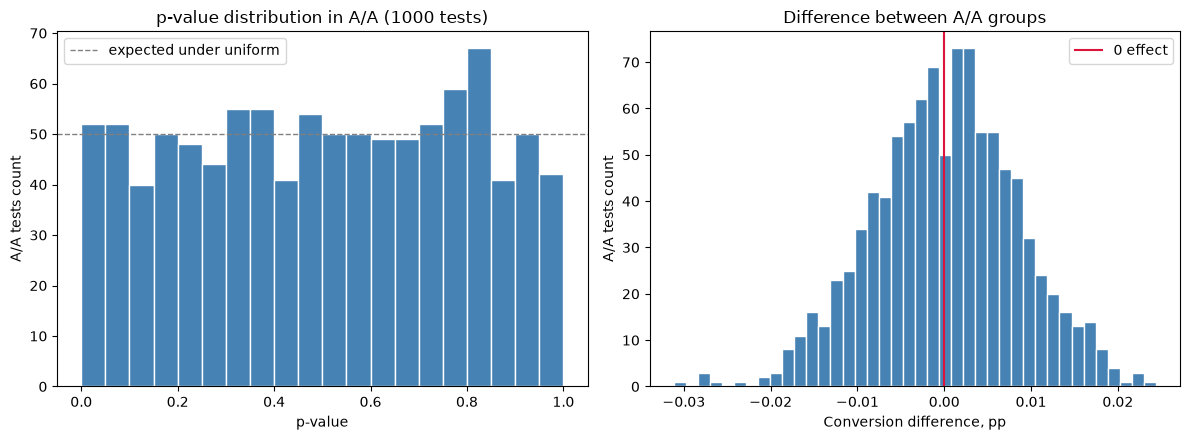

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.hist(p_values, bins=20, range=(0, 1), edgecolor="white", color="steelblue")
ax.axhline(len(p_values) / 20, color="gray", linestyle="--", linewidth=1,
           label="expected under uniform")
ax.set_xlabel("p-value")
ax.set_ylabel("A/A tests count")
ax.set_title("p-value distribution in A/A (1000 tests)")
ax.legend()

ax = axes[1]
ax.hist(np.array(diff_values) * 100, bins=40, edgecolor="white", color="steelblue")
ax.axvline(0, color="crimson", linewidth=1.5, label="0 effect")
ax.set_xlabel("Conversion difference, pp")
ax.set_ylabel("A/A tests count")
ax.set_title("Difference between A/A groups")
ax.legend()

plt.tight_layout()
plt.show()

## Peeking

In [5]:
aa_df = duckdb.sql("SELECT conversion FROM '../data/criteo.parquet' WHERE treatment = 0").df()

p_values = []

for _ in range(100):
    aa_df["treatment"] = (rng.random(len(aa_df)) < 0.85).astype(int)

    aa_df_days = np.array_split(aa_df, 20)

    for i in range(20):
        aa_df_day = pd.DataFrame(np.concatenate(aa_df_days[:i + 1]), columns=aa_df.columns)
        g = aa_df_day.groupby("treatment")["conversion"].agg(["mean", "size"])
        res = ztest_props(g["mean"][1], g["size"][1], g["mean"][0], g["size"][0])

        if res["p_value"] < 0.05:
            p_values.append(res["p_value"])
            break
    else:
        p_values.append(res["p_value"])

print("FPR:", sum(p < 0.05 for p in p_values) / len(p_values))

FPR: 0.2


## Conclusion

- **A/A tests:** control users were randomly split 85/15 into fake groups 1000 times (no real effect).
  FPR = 4.7% ≈ α = 5%, p-values are uniform → the z-test is well-calibrated.
  Random splits give differences of at most ~±0.02 p.p., far below the real A/B effect of +0.115 p.p.
- **Peeking:** the same A/A data was split into 20 "days" and tested after each day, stopping at the first p < 0.05.
  FPR grows to X% → checking results repeatedly inflates false positives.
  Our A/B test was analyzed once at the end, so it is not affected.